# Exercise 1: Training a GPT-style Transformer

In this exercise, you'll use the Hugging Face Transformers library to configure, train a GPT-style language model on the TinyStories dataset.

**Learning Objectives:**
- Understand GPT model configuration parameters
- Use the Transformers library for language modeling
- Configure model architecture (attention heads, layers, embedding size)
- Train a language model for next-token prediction
- Generate text using different decoding strategies
- Evaluate model performance with perplexity

**Key Concepts:**
- Model configuration vs model weights
- Attention heads and their relationship to model dimension
- Training arguments and hyperparameters
- Decoding strategies (greedy, sampling, beam search)

## Part 1: Setup and Load Data

In [2]:
# Install required packages
!pip install torch datasets transformers matplotlib tqdm accelerate -q

In [3]:
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from datasets import load_dataset

from transformers import (
    AutoTokenizer,
    GPT2Config,
    GPT2LMHeadModel,
    DataCollatorForLanguageModeling,
    Trainer,
    TrainingArguments
)
import math
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


In [4]:
# Load TinyStories dataset
print("Loading TinyStories dataset...")
dataset = load_dataset("roneneldan/TinyStories", split="train[:5000]")
print(f"Loaded {len(dataset)} stories")

# Use GPT-2 tokenizer (or you can load your custom BPE tokenizer from Exercise 0)
tokenizer = AutoTokenizer.from_pretrained('gpt2')
tokenizer.pad_token = tokenizer.eos_token

print(f"Tokenizer vocabulary size: {len(tokenizer)}")
print(f"Sample tokens: {list(tokenizer.get_vocab().keys())[:10]}")

Loading TinyStories dataset...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00004-2d5a1467fff108(…):   0%|          | 0.00/249M [00:00<?, ?B/s]

data/train-00001-of-00004-5852b56a2bd28f(…):   0%|          | 0.00/248M [00:00<?, ?B/s]

...

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Tokenizer vocabulary size: 50257
Sample tokens: ['Ġrespir', 'ĠPanasonic', 'ĠBrut', 'ustainable', 'Balance', 'Ġtug', 'Ġreceives', 'igators', 'Ġthose', 'Ġattainment']


## Part 2: Understanding Model Configuration

Before creating a model, you need to understand the key configuration parameters:

**Critical Parameters:**
- `vocab_size`: Size of the tokenizer vocabulary
- `n_positions`: Maximum sequence length the model can handle
- `n_embd`: Embedding dimension (hidden size)
- `n_layer`: Number of transformer blocks
- `n_head`: Number of attention heads
- `n_inner`: Dimension of feed-forward inner layer (typically 4 × n_embd)

**Important Constraint:** `n_embd` must be divisible by `n_head`

### Question 1: Understanding Attention Heads

**Before continuing, answer these questions:**

1. **If `n_embd = 256` and `n_head = 8`, what is the dimension of each attention head?**
   - YOUR ANSWER HERE: 32
   - Formula: head_dim = n_embd / n_head

2. **Why must `n_embd` be divisible by `n_head`?**
   - YOUR ANSWER HERE:

3. **What happens if you increase the number of heads while keeping `n_embd` constant?**
   - YOUR ANSWER HERE:

## Part 3: Configure Your GPT Model

Now configure your model architecture. You'll need to fill in the parameters.

In [5]:
# TODO: Configure your GPT model
# Fill in the parameters below based on your understanding

config = GPT2Config(
    vocab_size=len(tokenizer),              # Fixed: must match tokenizer
    n_positions=128,                         # Maximum sequence length

    # TODO: Fill in these parameters
    n_embd=256,        # Embedding dimension (try: 256, 384, 512)
    n_layer=4,       # Number of transformer blocks (try: 4, 6, 8)
    n_head=8,        # Number of attention heads (try: 4, 8, 16)
                        # REMEMBER: n_embd must be divisible by n_head!

    n_inner=1024,       # Feed-forward dimension (typically 4 × n_embd)

    # Additional parameters (already set)
    resid_pdrop=0.1,    # Residual dropout
    embd_pdrop=0.1,     # Embedding dropout
    attn_pdrop=0.1,     # Attention dropout
    activation_function="gelu_new"
)

print("Model Configuration:")
print(f"  Vocabulary size: {config.vocab_size}")
print(f"  Embedding dimension: {config.n_embd}")
print(f"  Number of layers: {config.n_layer}")
print(f"  Number of heads: {config.n_head}")
print(f"  Head dimension: {config.n_embd // config.n_head if config.n_head else 'N/A'}")
print(f"  Feed-forward dimension: {config.n_inner}")
print(f"  Max sequence length: {config.n_positions}")

Model Configuration:
  Vocabulary size: 50257
  Embedding dimension: 256
  Number of layers: 4
  Number of heads: 8
  Head dimension: 32
  Feed-forward dimension: 1024
  Max sequence length: 128


### Question 2: Model Size Trade-offs

**Answer these questions about your configuration:**

1. **What is the relationship between `n_embd`, `n_layer`, `n_head` and model capacity?**
   - YOUR ANSWER HERE:

2. **Why is `n_inner` typically set to 4 × `n_embd`?**
   - YOUR ANSWER HERE:

3. **What are the trade-offs between a small model (e.g., n_embd=128, n_layer=4) vs a large model (e.g., n_embd=512, n_layer=12)?**
   - YOUR ANSWER HERE:

## Part 4: Create the Model

Now instantiate the model with your configuration.

In [6]:
# Create model from config
model = GPT2LMHeadModel(config)
model = model.to(device)

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"\nModel created successfully!")
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Model size: ~{total_params * 4 / 1024**2:.2f} MB (fp32)")

# Show model architecture
print(f"\nModel architecture:")
print(model)


Model created successfully!
Total parameters: 16,058,112
Trainable parameters: 16,058,112
Model size: ~61.26 MB (fp32)

Model architecture:
GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 256)
    (wpe): Embedding(128, 256)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-3): 4 x GPT2Block(
        (ln_1): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=768, nx=256)
          (c_proj): Conv1D(nf=256, nx=256)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=1024, nx=256)
          (c_proj): Conv1D(nf=256, nx=1024)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((256,), eps=1e-05, elementwise_affi

## Part 5: Data Preparation

Prepare the dataset for causal language modeling (predicting next tokens).

In [7]:
# Tokenize the entire dataset
def tokenize_function(examples):
    """Tokenize text examples."""
    return tokenizer(
        examples['text'],
        truncation=True,
        max_length=128,
        padding=False,
        return_attention_mask=False
    )

print("Tokenizing dataset...")
tokenized_dataset = dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=dataset.column_names,
    desc="Tokenizing"
)

print(f"Tokenized {len(tokenized_dataset)} examples")

# Show example
example = tokenized_dataset[0]
print(f"\nExample tokenized sequence:")
print(f"  Length: {len(example['input_ids'])}")
print(f"  First 20 tokens: {example['input_ids'][:20]}")
print(f"  Decoded: {tokenizer.decode(example['input_ids'][:50])}...")

Tokenizing dataset...


Tokenizing:   0%|          | 0/5000 [00:00<?, ? examples/s]

Tokenized 5000 examples

Example tokenized sequence:
  Length: 128
  First 20 tokens: [3198, 1110, 11, 257, 1310, 2576, 3706, 20037, 1043, 257, 17598, 287, 607, 2119, 13, 1375, 2993, 340, 373, 2408]
  Decoded: One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.
...


In [8]:
# Create data collator for language modeling
# This automatically creates labels by shifting input_ids
data_collator = DataCollatorForLanguageModeling(
    tokenizer=tokenizer,
    mlm=False  # False = Causal LM (GPT), True = Masked LM (BERT)
)

print("Data collator created for causal language modeling")

Data collator created for causal language modeling


### Question 3: Causal vs Masked Language Modeling

**Answer these questions:**

1. **What is the difference between causal LM (GPT) and masked LM (BERT)?**
   - YOUR ANSWER HERE:

2. **Why do we set `mlm=False` for GPT-style models?**
   - YOUR ANSWER HERE:

3. **How does the DataCollator create labels for next-token prediction?**
   - Hint: Compare input_ids and labels
   - YOUR ANSWER HERE:

## Part 6: Configure Training

Set up training hyperparameters.

In [9]:
# TODO: Configure training arguments
# Fill in key hyperparameters

training_args = TrainingArguments(
    output_dir="./gpt_tinystories",

    # TODO: Fill in these training hyperparameters
    num_train_epochs=3,           # Number of epochs (try: 3, 5)
    per_device_train_batch_size=16, # Batch size (try: 8, 16, 32)
    learning_rate=1e-4,               # Learning rate (try: 5e-4, 3e-4, 1e-4)

    # Optimization settings
    warmup_steps=500,
    weight_decay=0.01,

    # Logging and saving
    logging_steps=100,
    save_steps=1000,
    save_total_limit=2,

    # Evaluation
    eval_strategy="no",

    # Misc
    report_to="none",
    remove_unused_columns=False,
)

print("Training configuration:")
print(f"  Epochs: {training_args.num_train_epochs}")
print(f"  Batch size: {training_args.per_device_train_batch_size}")
print(f"  Learning rate: {training_args.learning_rate}")
print(f"  Warmup steps: {training_args.warmup_steps}")

Training configuration:
  Epochs: 3
  Batch size: 16
  Learning rate: 0.0001
  Warmup steps: 500


### Question 4: Training Hyperparameters

**Answer these questions:**

1. **What is the relationship between batch size and training speed/memory usage?**
   - YOUR ANSWER HERE:

2. **What is the purpose of warmup steps in learning rate scheduling?**
   - YOUR ANSWER HERE:

## Part 7: Train the Model

Use the Hugging Face Trainer to train your model.

In [10]:
# Create Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_dataset,
    data_collator=data_collator,
)

print("Trainer created successfully!")
print(f"\nStarting training...")

Trainer created successfully!

Starting training...


In [11]:
# Train the model
train_result = trainer.train()

print("\nTraining completed!")
print(f"Training time: {train_result.metrics['train_runtime']:.2f} seconds")
print(f"Final loss: {train_result.metrics['train_loss']:.4f}")
print(f"Samples per second: {train_result.metrics['train_samples_per_second']:.2f}")

`loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Step,Training Loss
100,10.238100
200,8.947500
300,7.334400
400,5.880200
500,5.043200
600,4.574600
700,4.329400
800,4.206800
900,4.112900



Training completed!
Training time: 78.46 seconds
Final loss: 5.9911
Samples per second: 191.18


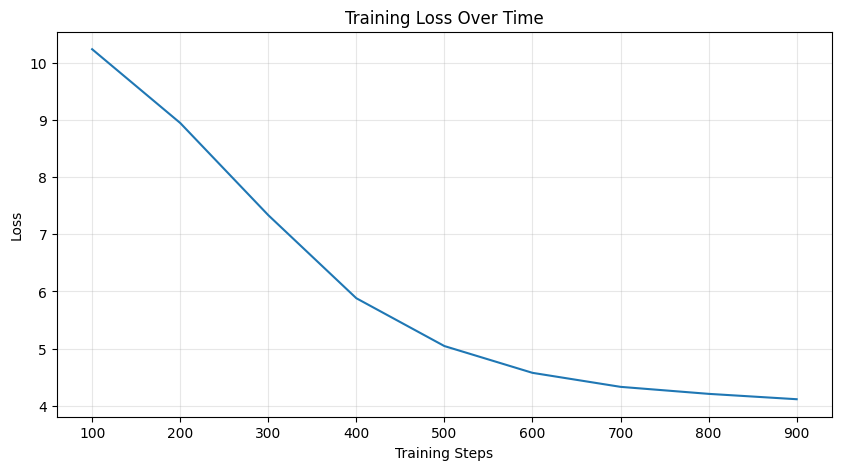


Loss decreased from 10.2381 to 4.1129


In [12]:
# Plot training loss
log_history = trainer.state.log_history
losses = [log['loss'] for log in log_history if 'loss' in log]
steps = [log['step'] for log in log_history if 'loss' in log]

plt.figure(figsize=(10, 5))
plt.plot(steps, losses)
plt.xlabel('Training Steps')
plt.ylabel('Loss')
plt.title('Training Loss Over Time')
plt.grid(alpha=0.3)
plt.show()

print(f"\nLoss decreased from {losses[0]:.4f} to {losses[-1]:.4f}")

## Part 8: Text Generation with Different Strategies

Now use your trained model to generate text using different decoding strategies.

### Strategy 1: Greedy Decoding

Always select the most likely next token.

In [13]:
def generate_text(prompt, strategy="greedy", max_length=100, **kwargs):
    """Generate text with different decoding strategies."""
    model.eval()

    # Encode prompt
    input_ids = tokenizer.encode(prompt, return_tensors='pt').to(device)

    # Generate based on strategy
    with torch.no_grad():
        if strategy == "greedy":
            output = model.generate(
                input_ids,
                max_length=max_length,
                pad_token_id=tokenizer.eos_token_id,
                do_sample=False  # Greedy decoding
            )
        elif strategy == "sampling":
            output = model.generate(
                input_ids,
                max_length=max_length,
                pad_token_id=tokenizer.eos_token_id,
                do_sample=True,
                temperature=kwargs.get('temperature', 1.0),
                top_k=kwargs.get('top_k', 50),
                top_p=kwargs.get('top_p', 0.95)
            )
        elif strategy == "beam_search":
            output = model.generate(
                input_ids,
                max_length=max_length,
                pad_token_id=tokenizer.eos_token_id,
                num_beams=kwargs.get('num_beams', 5),
                early_stopping=True
            )

    return tokenizer.decode(output[0], skip_special_tokens=True)

# Test greedy decoding
prompts = [
    "Once upon a time",
    "There was a little girl",
    "In a magical forest"
]

print("Greedy Decoding (deterministic)")
print("=" * 70)
for prompt in prompts:
    generated = generate_text(prompt, strategy="greedy", max_length=80)
    print(f"\nPrompt: {prompt}")
    print(f"Generated: {generated}")
    print("-" * 70)

The attention mask is not set and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.


Greedy Decoding (deterministic)

Prompt: Once upon a time
Generated: Once upon a time, there was a little girl named Lily. She loved to play with her mommy. She was very happy and she was very happy. She was very happy and she was very happy.

One day, she was very happy and said, "I'm so she was so she was so excited.

The little girl was so she was so she was so excited
----------------------------------------------------------------------

Prompt: There was a little girl
Generated: There was a little girl named Lily. She was very happy and she was very happy. She was very happy. She was very happy and she was very happy.

One day, she was very happy. She was very happy and she was so she was so she was so she was so she was so she was so she was so she was so she was so she was so she was
----------------------------------------------------------------------

Prompt: In a magical forest
Generated: In a magical forest. He was a little girl named Lily. She loved to play with her mom. 

### Strategy 2: Sampling with Temperature

Sample from the probability distribution over next tokens.

In [14]:
# TODO: Experiment with different temperatures
temperatures = [0.5, 0.8, 1.2]  # Add more if you want

prompt = "Once upon a time"

print("Sampling with Different Temperatures")
print("=" * 70)
print(f"Prompt: {prompt}\n")

for temp in temperatures:
    print(f"Temperature = {temp}:")
    for i in range(2):  # Generate 2 samples per temperature
        generated = generate_text(
            prompt,
            strategy="sampling",
            max_length=80,
            temperature=temp,
            top_k=50,
            top_p=0.95
        )
        print(f"  Sample {i+1}: {generated}")
    print()

Sampling with Different Temperatures
Prompt: Once upon a time

Temperature = 0.5:
  Sample 1: Once upon a time, there was a little girl named Lily. She loved to play with her mommy and her mommy. One day, she was so excited to play with her mommy. She was so she saw a big, Lily's mommy.

One day, Timmy said, "I can't want to play with her mommy.

"I can't
  Sample 2: Once upon a time, there was a little girl named Lily. She loved to play with her mom. She was very happy and her mommy. She loved to play with her mommy and her mommy and saw a big, "I can play with her mom.

One day, "I want to help her mommy, "It's mom said, "Let's mommy

Temperature = 0.8:
  Sample 1: Once upon a time there was a boy named I'm so he could play and he was so happy to play. He loved to play. One day, he tried to do it saw a big he loved to play in his mom.


The boy had a walk and he said, "I, "I. He saw a big, "I can it in the big, "I
  Sample 2: Once upon a time, there was a little girl named Lily. She 

### Strategy 3: Beam Search

Keep track of multiple candidate sequences.

In [15]:
# Test beam search
print("Beam Search (num_beams=5)")
print("=" * 70)

for prompt in prompts:
    generated = generate_text(
        prompt,
        strategy="beam_search",
        max_length=80,
        num_beams=5
    )
    print(f"\nPrompt: {prompt}")
    print(f"Generated: {generated}")
    print("-" * 70)

Beam Search (num_beams=5)

Prompt: Once upon a time
Generated: Once upon a time, there was a little girl named Lily. She loved to play with her mommy. One day, she wanted to play with her mommy.

One day, she saw a big, she saw a little girl named Lily. She wanted to play with her mommy.


One day, Lily's mom said, "Let's mommy, "I
----------------------------------------------------------------------

Prompt: There was a little girl
Generated: There was a little girl named Lily. She loved to play with her mommy. She loved to play with her mommy. One day, she was so excited to play with her mommy.

One day, she saw a little girl named Lily. She wanted to play with her mommy. She wanted to play with her mommy.


One day, she saw a
----------------------------------------------------------------------

Prompt: In a magical forest
Generated: In a magical forest, there was a little girl named Lily. She loved to play with her mommy. One day, she wanted to play with her mommy. 

One day, she

### Question 5: Generation Strategies

**Based on your experiments, answer these questions:**

1. **What is the difference between greedy decoding and sampling?**
   - YOUR ANSWER HERE:

2. **How does temperature affect the diversity and quality of generated text?**
   - Low temperature (e.g., 0.5): YOUR ANSWER HERE
   - High temperature (e.g., 1.2): YOUR ANSWER HERE

3. **What is beam search and how does it differ from greedy decoding?**
   - YOUR ANSWER HERE:

4. **What are `top_k` and `top_p` sampling? When would you use them?**
   - YOUR ANSWER HERE:

## Part 9: Model Evaluation with Perplexity

Compute perplexity to evaluate model performance.

In [16]:
def compute_perplexity(model, dataset, batch_size=16, max_samples=1000):
    """Compute perplexity on a dataset."""
    model.eval()

    # Create dataloader
    dataloader = DataLoader(
        dataset.select(range(min(max_samples, len(dataset)))),
        batch_size=batch_size,
        collate_fn=data_collator
    )

    total_loss = 0
    total_tokens = 0

    with torch.no_grad():
        for batch in tqdm(dataloader, desc="Computing perplexity"):
            # Move to device
            input_ids = batch['input_ids'].to(device)
            labels = batch['labels'].to(device)

            # Forward pass
            outputs = model(input_ids, labels=labels)
            loss = outputs.loss

            # Count tokens (exclude padding)
            num_tokens = (labels != -100).sum().item()

            total_loss += loss.item() * num_tokens
            total_tokens += num_tokens

    # Compute perplexity
    avg_loss = total_loss / total_tokens
    perplexity = math.exp(avg_loss)

    return perplexity, avg_loss

# Compute perplexity
perplexity, avg_loss = compute_perplexity(model, tokenized_dataset, batch_size=16)

print(f"\nModel Evaluation:")
print(f"  Average Loss: {avg_loss:.4f}")
print(f"  Perplexity: {perplexity:.2f}")

Computing perplexity: 100%|██████████| 63/63 [00:01<00:00, 34.99it/s]


Model Evaluation:
  Average Loss: 4.0730
  Perplexity: 58.73


### Question 6: Understanding Perplexity

**Answer these questions:**

1. **What is perplexity and what does it measure?**
   - YOUR ANSWER HERE:

2. **What does a lower perplexity indicate?**
   - YOUR ANSWER HERE:

3. **How is perplexity calculated from cross-entropy loss?**
   - Formula: YOUR ANSWER HERE
   - Interpretation: YOUR ANSWER HERE

## Part 10: Save Your Model

Save the trained model for later use.

In [17]:
# Save model and tokenizer
save_path = "./my_gpt_model"

model.save_pretrained(save_path)
tokenizer.save_pretrained(save_path)

print(f"Model saved to '{save_path}'")
print(f"\nYou can load it later with:")
print(f"  model = GPT2LMHeadModel.from_pretrained('{save_path}')")
print(f"  tokenizer = AutoTokenizer.from_pretrained('{save_path}')")

Model saved to './my_gpt_model'

You can load it later with:
  model = GPT2LMHeadModel.from_pretrained('./my_gpt_model')
  tokenizer = AutoTokenizer.from_pretrained('./my_gpt_model')


In [18]:
# Test loading the model
loaded_model = GPT2LMHeadModel.from_pretrained(save_path)
loaded_tokenizer = AutoTokenizer.from_pretrained(save_path)

print("Model loaded successfully!")
print(f"Parameters: {sum(p.numel() for p in loaded_model.parameters()):,}")

Model loaded successfully!
Parameters: 16,058,112
